# Gabriele's Notebook

In this notebook i test several models

In [1]:
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns
from plotly import graph_objects as go

# Utils
from tqdm.notebook import tqdm
from tabulate import tabulate

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import OneHotEncoder
import torch

# Custom modules
import Models as LSTM
import Dataset
import utils


# Set SEED
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## Data loading

We first load the dataframe from the parquet file.

In [2]:
#df = pd.read_parquet('../Data/LOBSTER/AMZN.parquet')
df = pd.read_parquet('../Data/FI-2010-Cleaned/NoAuctionMinMax/KESBV_NoAuction_MinMax.parquet')
df = df.head(20000)
target_cols = ['Label_10']

df.drop(columns=['Label_20','Label_30','Label_50','Label_100', 'Day'], inplace=True)

# Basic feature extraction
# df = utils.FeaturesExtractionLOB(df).extract()
#df["MP"] = (df["P_Ask_1"] + df["P_Bid_1"]) / 2

df.head()

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Label_10
0,0.601500,0.014369,0.60142,0.005417,0.602383,0.013564,0.600976,0.01135,0.602117,0.009126,...,0.003273,0.599387,0.003211,0.597691,0.002996,0.600175,0.008002,0.594319,0.002971,1.0
1,0.601500,0.008572,0.60142,0.005417,0.602824,0.011097,0.600976,0.01135,0.602558,0.007661,...,0.003500,0.602890,0.003676,0.599023,0.003273,0.605862,0.003325,0.598313,0.002846,1.0
2,0.601059,0.004939,0.60142,0.005417,0.601059,0.013564,0.600976,0.01135,0.601235,0.020223,...,0.003500,0.599387,0.003211,0.599023,0.003273,0.600175,0.008002,0.598313,0.002846,2.0
3,0.601059,0.013103,0.60142,0.005417,0.601942,0.064118,0.600976,0.01135,0.602117,0.047769,...,0.003273,0.602890,0.003676,0.597691,0.002996,0.605862,0.003325,0.594319,0.002971,1.0
4,0.601059,0.013103,0.60142,0.005417,0.601942,0.064118,0.600976,0.01135,0.602117,0.047769,...,0.003273,0.602890,0.003676,0.597691,0.002996,0.605862,0.003325,0.594319,0.002971,0.0


In [3]:
# One hot encoding of the 3-values label
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe.fit(df[target_cols])
y = ohe.transform(df[target_cols])
X = df.drop(columns=target_cols).values

# Split covariates and response variable(s)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)



# Standardize the covariates
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

# Build tensors 
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train, dtype=torch.float32).to(device)
X_val = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val = torch.tensor(y_val, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test = torch.tensor(y_test, dtype=torch.float32).to(device)

# Build TimeSeriesDataset
SEQ_LEN_X = 10
SEQ_LEN_Y = 1
OFFSET = 10
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = True
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = True
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = True
)

# Build TimeSeriesLoader
BATCH_SIZE = 64
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = BATCH_SIZE,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = BATCH_SIZE,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

In [4]:
print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 13980 samples
Test dataset: 2980 samples


## Models

### Aragosta

The model has 166691 parameters


Training:   0%|          | 0/3 [00:00<?, ?it/s]

/orfeo/cephfs/home/dssc/gpintus/Jupyter/jupyter/lib64/python3.9/site-packages/torch/nn/modules/conv.py:456: UserWarning: Attempt to open cnn_infer failed: handle=0 error: libcudnn_cnn_infer.so.8: cannot open shared object file: No such file or directory (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:81.)
  return F.conv2d(input, weight, bias, self.stride,


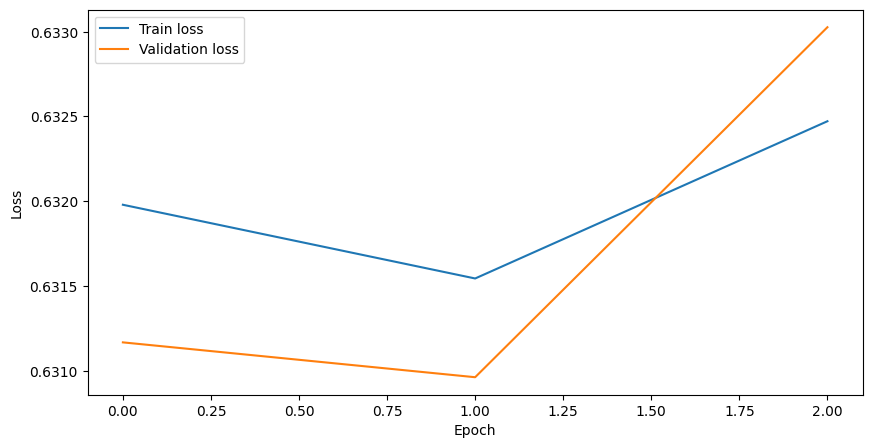

In [5]:
# Model parameters
INPUT_SIZE = X_train.shape[1]
OUTPUT_SIZE = y_train.shape[1]
HIDDEN_SIZE = 32

# LSTM
LSTM_SIZE = 64
LSTM_LAYERS = 2

# CNN
CONV_CHANNELS = 32
INCEPTION_CHANNELS = 64

# Optimizer parameters
LEARNING_RATE = 1e-3

# Build the model
model = LSTM.Aragosta(
    input_size = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    lstm_size = LSTM_SIZE,
    lstm_layers = LSTM_LAYERS,
    conv_channels = CONV_CHANNELS,
    inception_channels = INCEPTION_CHANNELS,
).to(device)

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Loss function
criterion = torch.nn.BCEWithLogitsLoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 3,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [28]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)

print(f'sMAPE: {utils.sMAPE(true,pred):.1f}%')

sMAPE: 198.9%


In [29]:
pred.mean(), pred.std()

(0.00796138, 0.0012581855)

In [16]:
# Compute the confusion matrix
cm = confusion_matrix(true.round(0), pred.round(0))

# Plot the confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['0', '1', '2'], yticklabels=['0', '1', '2'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

ValueError: multilabel-indicator is not supported

### Basic LSTM

In [ ]:
dataset_train.channels = False
dataset_val.channels = False
dataset_test.channels = False

dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = BATCH_SIZE,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = BATCH_SIZE,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

In [ ]:
# Model parameters
INPUT_SIZE = X_train.shape[1]
OUTPUT_SIZE = y_train.shape[1]
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.0
# Optimizer parameters
LEARNING_RATE = 1e-3

# Build the model
model = LSTM.LSTM(
    input_size = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    num_layers = NUM_LAYERS,
    dropout = DROPOUT
).to(device)

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Loss function
criterion = torch.nn.MSELoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 3,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)

print(f'sMAPE: {utils.sMAPE(true,pred):.1f}%')

#fig = go.Figure()
#fig.add_trace(go.Scatter(x=np.arange(len(true)), y=true, mode='lines', name='True'))
#fig.add_trace(go.Scatter(x=np.arange(len(pred)), y=pred, mode='lines', name='Predicted'))
#fig.show()
plt.plot(true, label='True')
plt.plot(pred, label='Pred')
plt.legend()
plt.show()

### Joel's model

In [ ]:

# Model parameters
INPUT_SIZE = X_train.shape[1]
HIDDEN_SIZE = 64
NUM_LAYERS = 2
OUTPUT_SIZE = y_train.shape[1]
DROPOUT = 0.0
# Optimizer parameters
LEARNING_RATE = 1e-3

# Build the model
model = LSTM.LSTM1(
    input_size = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    num_layers = NUM_LAYERS,
    dropout = DROPOUT
).to(device)

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Loss function
criterion = torch.nn.MSELoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 3,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)

In [ ]:
print(f'sMAPE: {utils.sMAPE(true,pred):.1f}%')

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=np.arange(len(true)), y=true, mode='lines', name='True'))
fig.add_trace(go.Scatter(x=np.arange(len(pred)), y=pred, mode='lines', name='Predicted'))
fig.show()

### Astice

<img src="../astice.png" width="200" >

In [ ]:
# Model parameters
INPUT_SIZE = X_train.shape[1]
OUTPUT_SIZE = y_train.shape[1]
HIDDEN_SIZE = 64

# LSTM
LSTM_SIZE = 64
LSTM_LAYERS = 2

# CMM
SMOOTH_CONV_CHANNELS = 4

# Optimizer parameters
LEARNING_RATE = 1e-3

# Build the model
model = LSTM.Astice(
    input_size = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    lstm_size = LSTM_SIZE,
    lstm_layers = LSTM_LAYERS,
    smooth_conv_channels = SMOOTH_CONV_CHANNELS
).to(device)

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Loss function
criterion = torch.nn.MSELoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 3,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)

In [ ]:
print(f'sMAPE: {utils.sMAPE(true,pred):.1f}%')

In [ ]:
#fig = go.Figure()
#fig.add_trace(go.Scatter(x=np.arange(len(true)), y=true, mode='lines', name='True'))
#fig.add_trace(go.Scatter(x=np.arange(len(pred)), y=pred, mode='lines', name='Predicted'))
#fig.show()
plt.plot(true, label='True')
plt.plot(pred, label='Pred')
plt.legend()
plt.show()